# Tutorial 5: Parametric problems

Parameters can be treated as additional coordinates, so that a **single solve returns the solution
for all parameter values**. Consider a bar on $[0,1]$ with a variable stiffness and an elastic
support at its tip,

$$
-\big(a(x;\xi_1)\,u'\big)' = 1, \qquad u(0)=0, \qquad a\,u'(1) + k(\xi_2)\,u(1) = 0,
$$

with $a=1+0.5\,\xi_1 x$ and $k=10^{\xi_2}$, for parameters $\xi_1,\xi_2\in[-1,1]$. We solve for
$u(x;\xi_1,\xi_2)$ at once, and evaluate the tip displacement $u(1;\xi)$ over the whole parameter
space.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seemps.analysis.cross import BlackBoxLoadMPS, CrossStrategyDMRG, cross_interpolation
from seemps.analysis.mesh import ChebyshevInterval, Mesh, mps_to_mesh_matrix
from seemps.state import MPS

from seemps_galerkin import (
    BoundaryFace,
    BoundaryProblem,
    BulkProblem,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
    TensorField,
)
from seemps_galerkin.mps.factories import mps_identity, mps_zeros
from seemps_galerkin.mps.factories.transform import mps_chebyshev_transform
from seemps_galerkin.solve import solve_dense_bvp, solve_mps_bvp


def tci(func, mesh):
    sites = [int(np.log2(N)) for N in mesh.dimensions]
    black_box = BlackBoxLoadMPS(
        lambda points: func(*points),
        mesh,
        map_matrix=mps_to_mesh_matrix(sites),
        physical_dimensions=[2] * sum(sites),
    )
    return cross_interpolation(black_box, CrossStrategyDMRG(tol=1e-12)).mps

## 1. Parameters as coordinates

The mesh has three coordinates, $(x,\xi_1,\xi_2)$, each with Chebyshev nodes. The equation has no
derivatives along the parameters, so only `principal[0, 0]` is set; integrating the weak form over
the parameters is then equivalent to solving for every parameter value at once (as in stochastic
Galerkin methods). Fields may depend on any coordinate.

In [2]:
n_x, n_ξ = 5, 4
sites = [n_x, n_ξ, n_ξ]
x_interval = ChebyshevInterval(0.0, 1.0, 2**n_x, endpoints=False)
ξ_interval = ChebyshevInterval(-1.0, 1.0, 2**n_ξ, endpoints=False)
mesh = Mesh([x_interval, ξ_interval, ξ_interval])
n = sum(sites)

principal = TensorField[MPS]((3, 3, 1, 1), mesh.dimensions)
principal[0, 0, 0, 0] = tci(lambda x, ξ1, ξ2: 1 + 0.5 * ξ1 * x, mesh)
source = TensorField[MPS]((1,), mesh.dimensions)
source[0] = mps_identity(n)
bulk = BulkProblem(mesh, principal, TensorField[MPS]((1, 1), mesh.dimensions), source)

## 2. Boundary conditions

The faces normal to $x$ are functions of the parameters, so the Robin coefficient $k(\xi_2)$ is a
field on the face mesh $(\xi_1,\xi_2)$. The faces normal to the parameters take empty Robin
conditions, which add nothing.

In [3]:
face_mesh = Mesh([ξ_interval, ξ_interval])
conditions = []

data = TensorField[MPS]((1,), face_mesh.dimensions)
data[0] = mps_zeros(2 * n_ξ)
conditions.append(DirichletBoundaryCondition(BoundaryFace(0, is_left=True), data))

support = TensorField[MPS]((1, 1), face_mesh.dimensions)
support[0, 0] = tci(lambda ξ1, ξ2: 10.0**ξ2, face_mesh)
conditions.append(RobinBoundaryCondition(BoundaryFace(0, is_left=False), support, TensorField[MPS]((1,), face_mesh.dimensions)))

for dim in (1, 2):
    shape = mesh.dimensions[:dim] + mesh.dimensions[dim + 1 :]
    for is_left in (True, False):
        conditions.append(RobinBoundaryCondition(BoundaryFace(dim, is_left), TensorField[MPS]((1, 1), shape), TensorField[MPS]((1,), shape)))

boundary = BoundaryProblem(mesh, conditions)
ψ = solve_mps_bvp(bulk, boundary)
print(f"{2**n} coefficients, stored with bond dimension {ψ.max_bond_dimension()}")

8192 coefficients, stored with bond dimension 13


## 3. Working with the compressed solution

The tip displacement is $u(1;\xi)=\sum_j c_j(\xi)\,T_j(1)=\sum_j c_j(\xi)$, since $T_j(1)=1$. In the
QTT, this sum over the $x$ coefficients is a contraction of each $x$ site with the vector
$(1,1)$, which leaves a QTT over the parameters only, without expanding the solution. Its inverse
Chebyshev transform gives $u(1;\xi)$ on the parameter nodes.

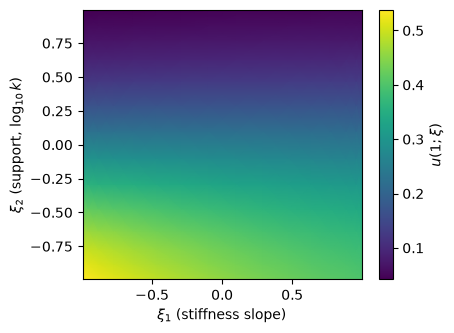

In [4]:
cores = list(ψ)
carry = np.ones((1,))
for core in cores[:n_x]:
    carry = carry @ core.sum(axis=1)
first = np.einsum("a,aib->ib", carry, cores[n_x])[None]
ψ_tip = MPS([first, *cores[n_x + 1 :]])
tip = mps_chebyshev_transform(ψ_tip, [n_ξ, n_ξ], inverse=True).to_vector().reshape(2**n_ξ, 2**n_ξ)

ξ = ξ_interval.to_vector()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
image = ax.pcolormesh(ξ, ξ, tip.T, shading="gouraud")
fig.colorbar(image, ax=ax, label="$u(1;\\xi)$")
ax.set_xlabel(r"$\xi_1$ (stiffness slope)")
ax.set_ylabel(r"$\xi_2$ (support, $\log_{10} k$)")
plt.show()

## 4. Check against individual solves

For a few parameter nodes, we solve the 1D problem directly with the dense solver and compare the
tip displacement.

In [5]:
def tip_displacement(ξ1, ξ2):
    N = 2**n_x
    mesh_1d = Mesh([x_interval])
    x = x_interval.to_vector()
    principal = TensorField[np.ndarray]((1, 1, 1, 1), (N,))
    principal[0, 0, 0, 0] = 1 + 0.5 * ξ1 * x
    source = TensorField[np.ndarray]((1,), (N,))
    source[0] = np.ones(N)
    bulk = BulkProblem(mesh_1d, principal, TensorField[np.ndarray]((1, 1), (N,)), source)
    left = TensorField[np.ndarray]((1,), ())
    left[0] = np.zeros(1)
    support = TensorField[np.ndarray]((1, 1), ())
    support[0, 0] = np.array([10.0**ξ2])
    boundary = BoundaryProblem(
        mesh_1d,
        [
            DirichletBoundaryCondition(BoundaryFace(0, True), left),
            RobinBoundaryCondition(BoundaryFace(0, False), support, TensorField[np.ndarray]((1,), ())),
        ],
    )
    return float(np.sum(solve_dense_bvp(bulk, boundary)))  # sum of coefficients = u(1)


for i, j in ((0, 0), (5, 12), (15, 3), (9, 9)):
    reference = tip_displacement(ξ[i], ξ[j])
    print(f"ξ = ({ξ[i]:+.3f}, {ξ[j]:+.3f}): parametric {tip[i, j]:.8f}, direct {reference:.8f}")

ξ = (-0.995, -0.995): parametric 0.53772653, direct 0.53772651
ξ = (-0.471, +0.773): parametric 0.07017460, direct 0.07017460
ξ = (+0.995, -0.773): parametric 0.38091391, direct 0.38091390
ξ = (+0.290, +0.290): parametric 0.16918638, direct 0.16918637


## Summary

- Parameters are extra mesh coordinates without derivatives; their faces take empty Robin
  conditions.
- Coefficients, sources and boundary data may depend on the parameters.
- One solve gives the solution for all parameter values. Quantities of interest can be extracted
  by contracting the compressed solution, without expanding it.